In [1]:
%matplotlib widget

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# importing the data
df1 = pd.read_csv("Yellow Taxi Trips - Week 1.csv")
df2 = pd.read_csv("Yellow Taxi Trips - Week 2.csv")
df3 = pd.read_csv("Yellow Taxi Trips - Week 3.csv")
df4 = pd.read_csv("Yellow Taxi Trips - Week 4.csv")
df5 = pd.read_csv("Yellow Taxi Trips - Week 5.csv")

In [3]:
# concatenating the dataframes into a single dataframe
df = pd.concat([df1, df2, df3, df4, df5])

In [4]:
df.head(10)

,ID,Pickup_Date,Week_No,Passenger_Count,Trip_Distance,Tip_Amount,Total_Amount,Airport_Fee,Payment_Type,Rate_Code
0,418880,07/01/2022,1,1,17.45,0.0,79.05,0.0,Credit card,Newark
1,266865,05/01/2022,1,1,18.25,0.0,84.05,0.0,Cash,Newark
2,227117,04/01/2022,1,1,18.35,0.0,84.05,0.0,Credit card,Newark
3,193883,04/01/2022,1,1,17.70,0.0,78.05,0.0,Credit card,Newark
4,193349,04/01/2022,1,1,16.01,0.0,75.05,0.0,Cash,Newark
5,107100,02/01/2022,1,1,18.59,0.0,82.55,0.0,Cash,Newark
6,105095,02/01/2022,1,1,17.39,0.0,85.55,0.0,Cash,Newark
7,101542,02/01/2022,1,1,27.67,0.0,105.55,0.0,Cash,Newark
8,101206,02/01/2022,1,1,13.53,0.0,73.05,0.0,Cash,Newark
9,100809,02/01/2022,1,1,19.53,0.0,84.05,0.0,Cash,Newark


In [5]:
# getting the total number of trips for each payment type
trips = df.groupby(by = 'Payment_Type', as_index = False)['ID'].count()
trips

,Payment_Type,ID
0,Cash,492794
1,Credit card,1874544


In [6]:
trips.rename(columns = {'ID' : 'Trips'}, inplace = True)
trips

C:\Users\robfr\AppData\Local\Temp\ipykernel_36504\2702514751.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  trips.rename(columns = {'ID' : 'Trips'}, inplace = True)


,Payment_Type,Trips
0,Cash,492794
1,Credit card,1874544


In [7]:
plt.bar?

Signature:
plt.bar(
    x: 'float | ArrayLike',
    height: 'float | ArrayLike',
    width: 'float | ArrayLike' = 0.8,
    bottom: 'float | ArrayLike | None' = None,
    *,
    align: "Literal['center', 'edge']" = 'center',
    data: 'DataParamType' = None,
    **kwargs,
) -> 'BarContainer'
Docstring:
Make a bar plot.

The bars are positioned at *x* with the given *align*\ment. Their
dimensions are given by *height* and *width*. The vertical baseline
is *bottom* (default 0).

Many parameters can take either a single value applying to all bars
or a sequence of values, one for each bar.

Parameters
----------
x : float or array-like
    The x coordinates of the bars. See also *align* for the
    alignment of the bars to the coordinates.

    Bars are often used for categorical data, i.e. string labels below
    the bars. You can provide a list of strings directly to *x*.
    ``bar(['A', 'B', 'C'], [1, 2, 3])`` is often a shorter and more
    convenient notation compared to
    ``bar(rang

<BarContainer object of 2 artists>

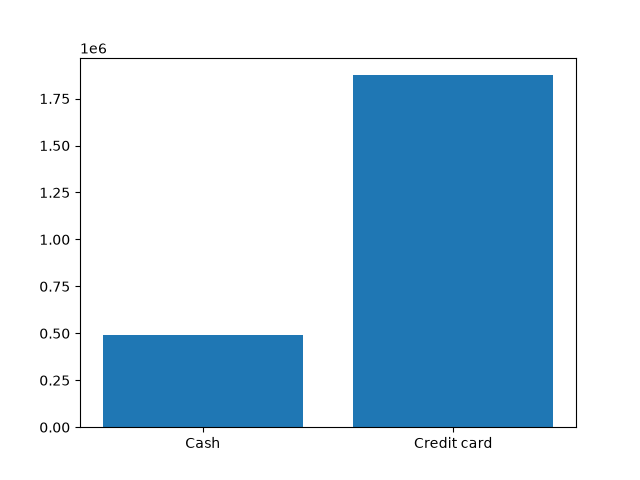

In [11]:
# creating a bar chart
plt.figure()
plt.bar(trips['Payment_Type'], trips['Trips'])

<BarContainer object of 2 artists>

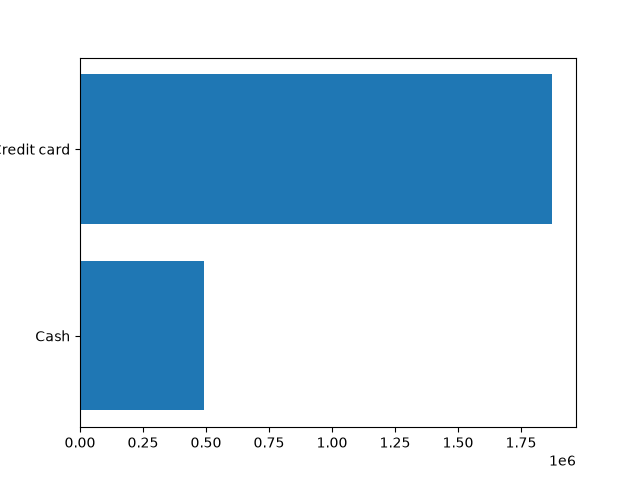

In [10]:
plt.figure()
plt.barh(trips['Payment_Type'], trips['Trips'])

In [12]:
# creating a stacked bar chart
# preparing the data for the stacked bar chart
weekly_trips = df.pivot_table(values = 'ID', index = 'Week_No', columns = 'Payment_Type', aggfunc = 'count')
weekly_trips

Payment_Type,Cash,Credit card
Week_No,,
1,116387,361622
2,112151,426697
3,112264,453494
4,118142,489046
5,33850,143685


In [14]:
weekly_trips = weekly_trips.reset_index()
weekly_trips

Payment_Type,Week_No,Cash,Credit card
0,1,116387,361622
1,2,112151,426697
2,3,112264,453494
3,4,118142,489046
4,5,33850,143685


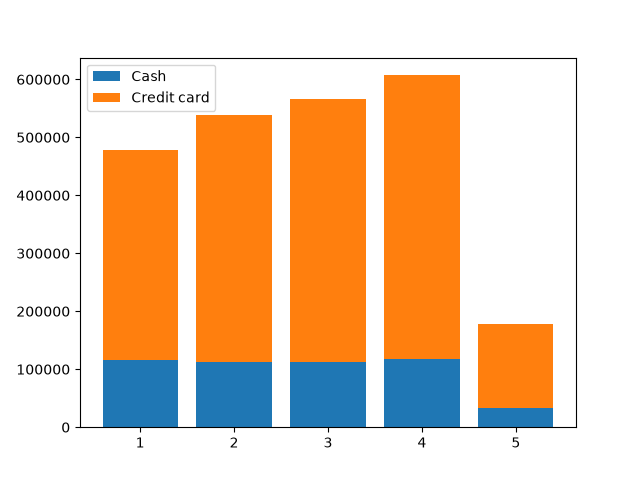

In [18]:
plt.figure()
plt.bar(weekly_trips['Week_No'], weekly_trips['Cash'], label = 'Cash')
plt.bar(weekly_trips['Week_No'], weekly_trips['Credit card'], bottom = weekly_trips['Cash'], label = 'Credit card')
plt.legend()

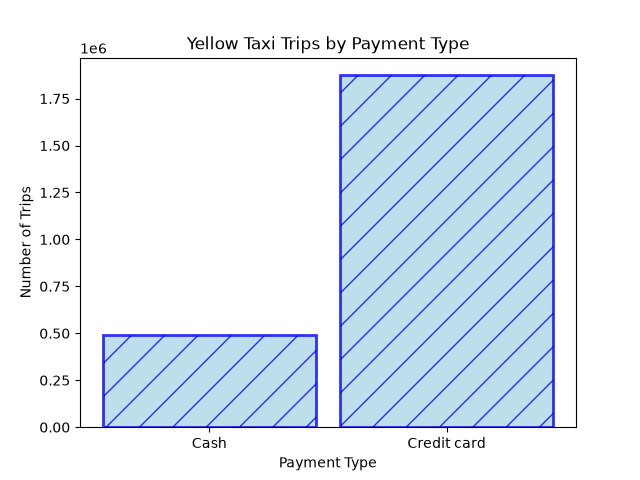

In [31]:
# creating the chart
plt.figure()
plt.bar(trips['Payment_Type'], trips['Trips'], width = 0.9, alpha = 0.8, color = 'lightblue', edgecolor = 'blue', linewidth = 2, hatch = '/')
plt.title('Yellow Taxi Trips by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Number of Trips')
plt.savefig('yellow-taxi-trips-by-payment-type.png', dpi = 300, bbox_inches = 'tight')